# SIMVI archetypes vs EMT states

**Environment:** `conda activate simvi_env`

`05_simvi_run.ipynb` trained SIMVI and decomposed its spatial/interaction
latent into 7 archetypal spatial-effect programs (`adata.obs["Archetype 1"]`
… `"Archetype 7"]`, a softmax-like membership that sums to 1 per cell). This
notebook asks, for each archetype: *does it associate with EMT state, and
with which neighbouring cell types?* — five ways:

1. **Fisher exact test** — is an archetype's membership enriched in a
   particular EMT state (vs the rest), among tumour cells?
2. **State-neighbour heatmap per archetype** — section 4 of `05_simvi_run`'s
   attention-based "which cell type is near which EMT state" heatmap,
   recomputed within each archetype's cell subset, all 7 in one panel.
3. **State-neighbour spoke networks per archetype** — same idea via
   `plot_state_neighbours`, one grid of (archetype × state) spoke plots.
4. **Intrinsic vs spatial-effect gene scatter**, now labelling *every*
   significant gene rather than a fixed cutoff.
5. **squidpy neighbourhood enrichment per archetype** — a model-free
   cross-check, recomputed within each archetype's cell subset.

## Requires the attention matrix saved in `adata.obsp`

Item 2/3 need the trained GAT's cell–cell attention matrix
(`model.get_attention(edge_index)`), which `05_simvi_run.ipynb` computed
but, until now, never wrote to disk. Its save cell has been updated to
also do:

```python
adata.obsp["simvi_attention"] = attn
```

If you already ran `05_simvi_run.ipynb` before this change: **you don't
need to retrain** — `model`, `attn` and `adata` are still in that
notebook's kernel memory, so just re-run its (now-updated) save cell and
reload the `.h5ad` here. The cell below checks for this and tells you
plainly if it's missing.

## A real data quirk you'll see below

Archetypes are spatial-effect programs fit across the *whole* tissue, not
tumour cells specifically — some archetypes may turn out to be almost
purely stromal/immune niches with very few or even zero tumour cells in
them. That's an informative finding, not a bug: items 1–3 (which need a
per-state, per-archetype tumour-cell sample) will show mostly-empty panels
for those archetypes, while item 5 (squidpy, all cells regardless of
tumour status) stays informative for every archetype. Cell counts are
printed up front so this isn't a surprise later.

In [16]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import fisher_exact, ttest_ind

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 12

FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

EMT_MAP = {0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"}

## 1. Load data

In [17]:
adata = sc.read_h5ad("processed_data/xenium_v1_hallmark_simvi_results.h5ad")

ARCHETYPE_COLS = [c for c in adata.obs.columns if c.startswith("Archetype ")]
assert ARCHETYPE_COLS, (
    "No 'Archetype N' columns in adata.obs -- did 05_simvi_run.ipynb's get_se step run?"
)
assert "simvi_attention" in adata.obsp, (
    "adata.obsp['simvi_attention'] is missing. Sections 2-3 below need the trained GAT's "
    "attention matrix, which 05_simvi_run.ipynb's save cell now persists via "
    "`adata.obsp['simvi_attention'] = attn`. Re-run just that (updated) cell in "
    "05_simvi_run.ipynb -- model/attn/adata are already in memory there, so this does NOT "
    "require retraining -- then reload this file."
)

attn = adata.obsp["simvi_attention"].tocsr()
print(f"{len(ARCHETYPE_COLS)} archetypes: {ARCHETYPE_COLS}")
adata

7 archetypes: ['Archetype 1', 'Archetype 2', 'Archetype 3', 'Archetype 4', 'Archetype 5', 'Archetype 6', 'Archetype 7']


AnnData object with n_obs × n_vars = 139320 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'dataset', 'celltype_major', 'celltype_minor', 'subclone_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'EMT_hallmarks', 'myCAF_signtaure', 'hypoxia_hallmarks', 'angio_hallmarks', 'EMT_hallmarks_alltumour', 'EMT_hallmarks_visium', 'labels', 'labels_three', 'Barcode', 'Cluster', 'EMT_score', 'tumour_cells', 'state_label', 'EMT_state', '_scvi_batch', '_scvi_labels', 'Archetype 1', 'Archetype 2', 'Archetype 3', 'Archetype 4', 'Archetype 5', 'Archetype 6', 'Archetype 7', 'celltype_or_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1

## 2. Archetype subsets

Membership scores sum to 1 per cell, so `> 0.5` gives clean, mutually
exclusive subsets (at most one archetype can exceed 0.5 per cell) — the
same convention `model.get_se(positivity_filter=...)` uses internally.
~48% of cells won't clear 0.5 for *any* archetype (mixed/ambiguous niche
membership) and are simply absent from every subset below.

In [18]:
archetype_membership = adata.obs[ARCHETYPE_COLS] > 0.5
tumour_mask = (adata.obs["state_label"] >= 0).values

n_multi = int((archetype_membership.sum(axis=1) > 1).sum())
print(f"cells assigned to >1 archetype at once (should be 0): {n_multi}")
print()

summary = pd.DataFrame({
    "n_cells": archetype_membership.sum(),
    "pct_all_cells": (100 * archetype_membership.mean()).round(1),
    "n_tumour_cells": archetype_membership.loc[tumour_mask].sum(),
    "pct_of_tumour_cells": (100 * archetype_membership.loc[tumour_mask].mean()).round(1),
})
summary

cells assigned to >1 archetype at once (should be 0): 0



,n_cells,pct_all_cells,n_tumour_cells,pct_of_tumour_cells
Archetype 1,4520,3.2,1884,3.7
Archetype 2,29419,21.1,27294,52.9
Archetype 3,4064,2.9,8,0.0
Archetype 4,7954,5.7,6975,13.5
Archetype 5,13316,9.6,431,0.8
Archetype 6,10305,7.4,0,0.0
Archetype 7,5116,3.7,1,0.0


## 3. Fisher exact test: archetype membership vs cell type / EMT state

For each `(archetype, celltype_or_state category)` pair, a 2x2 table
(`in archetype` x `in this category`, vs everything else), one-sided
Fisher exact test (`alternative="greater"`): is the archetype
over-represented for that category specifically?

The background population differs by category type: EMT states (`EPI`,
`H-EPI`, `H-MES`, `MES`) only exist among tumour cells, so those rows are
tested against the **tumour-cell population only** -- matching the
permutation baseline `state_neighbour_associations` in section 4 already
uses (target state cells vs random *tumour* cells), and matching what a
tumour-only EMT-state Fisher test would show on its own. Every other
category (CAFs, Macrophage, endothelial subtypes, ...) is tested against
**all cells**, since those aren't tumour-restricted to begin with. Mixing
the two populations in one test would dilute or inflate EMT-state
significance depending on how large the non-tumour background is -- e.g.
`Archetype 3`/`Archetype 5` vs `MES` are only significant against the
tumour-only background (p=3.8e-04, p=1.5e-110) and look non-significant
(p=1.0) against all cells, since non-tumour cells outnumber tumour cells
~1.7:1 in this dataset and dominate the "not MES" side of the table.

In [19]:
def archetype_celltype_fisher(
    adata, archetype_cols, category_key="celltype_or_state", state_key="state_label",
    emt_states=None, threshold=0.5,
):
    '''2x2 Fisher exact test (one-sided, "greater") per (archetype, category).
    `emt_states` categories (only ever tumour cells) are tested against the
    tumour-cell population only; every other category is tested against
    all cells. See section 3 markdown for why the population has to differ
    by category.'''
    categories = adata.obs[category_key].astype(str).values
    tumour = adata.obs[state_key].values >= 0
    emt_states = set(emt_states or [])
    unique_categories = sorted(set(categories))
    records = []
    for arch in archetype_cols:
        in_arch_full = (adata.obs[arch] > threshold).values
        for cat in unique_categories:
            population = tumour if cat in emt_states else np.ones_like(tumour, dtype=bool)
            in_arch = in_arch_full & population
            in_cat = (categories == cat) & population
            a = int(np.sum(in_arch & in_cat))
            b = int(np.sum(in_arch & ~in_cat))
            c = int(np.sum(~in_arch & in_cat & population))
            d = int(np.sum(~in_arch & ~in_cat & population))
            odds_ratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
            records.append({
                "archetype": arch, "category": cat,
                "n_in_archetype": a + b, "n_in_archetype_and_category": a,
                "odds_ratio": odds_ratio, "p_value": p,
            })
    return pd.DataFrame(records)


fisher_df = archetype_celltype_fisher(
    adata, ARCHETYPE_COLS, category_key="celltype_or_state",
    state_key="state_label", emt_states=EMT_MAP.values(),
)
fisher_df.sort_values("p_value").head(15)

,archetype,category,n_in_archetype,n_in_archetype_and_category,odds_ratio,p_value
177,Archetype 7,Endothelial ACKR1,5116,1637,81.433504,0.000000e+00
166,Archetype 6,T cells CD4+,10305,2472,12.112853,0.000000e+00
167,Archetype 6,T cells CD8+,10305,1261,7.067498,0.000000e+00
147,Archetype 6,DCs,10305,1363,7.193609,0.000000e+00
140,Archetype 6,B cells Memory,10305,693,18.494057,0.000000e+00
58,Archetype 3,CAFs MSC iCAF-like,4064,2301,18.427785,0.000000e+00
15,Archetype 1,Luminal Progenitors,4520,1563,33.579648,0.000000e+00
115,Archetype 5,CAFs myCAF-like,13316,5324,13.871347,0.000000e+00
178,Archetype 7,Endothelial CXCL12,5116,896,35.674956,0.000000e+00
180,Archetype 7,Endothelial RGS5,5116,925,8.618533,0.000000e+00


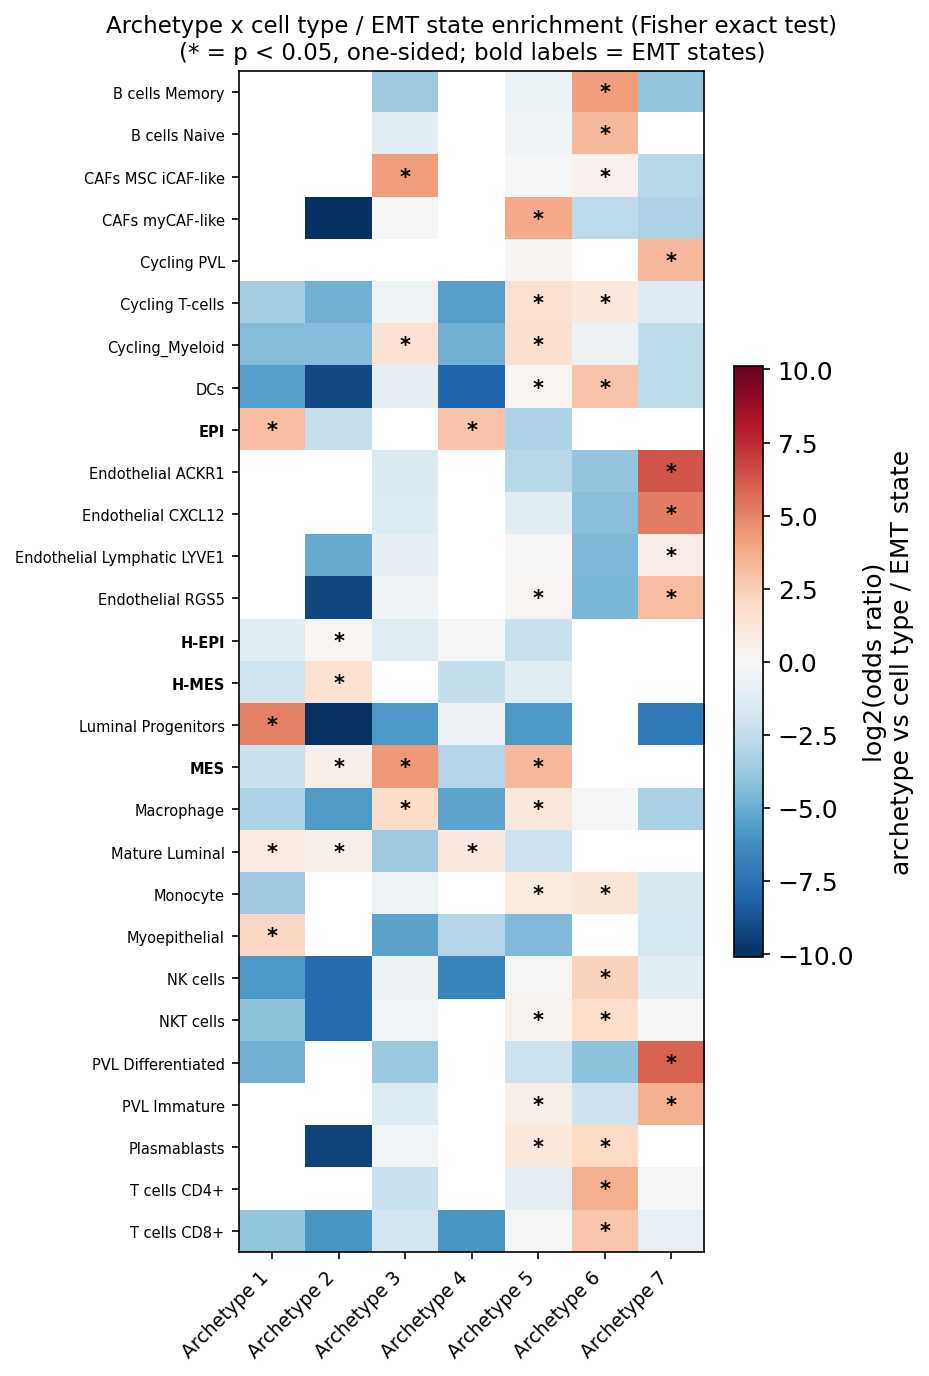

In [20]:
categories_order = sorted(fisher_df["category"].unique())
odds_pivot = fisher_df.pivot(index="category", columns="archetype", values="odds_ratio").reindex(index=categories_order, columns=ARCHETYPE_COLS)
p_pivot = fisher_df.pivot(index="category", columns="archetype", values="p_value").reindex(index=categories_order, columns=ARCHETYPE_COLS)

log_odds = np.log2(odds_pivot.replace(0, np.nan))
finite = log_odds.values[np.isfinite(log_odds.values)]
vmax = np.abs(finite).max() if finite.size else 1.0

fig, ax = plt.subplots(figsize=(0.6 * len(ARCHETYPE_COLS) + 2, 0.28 * len(categories_order) + 1.5))
im = ax.imshow(log_odds.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(ARCHETYPE_COLS)))
ax.set_xticklabels(ARCHETYPE_COLS, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(categories_order)))
ax.set_yticklabels(categories_order, fontsize=7)
for tick_label, cat in zip(ax.get_yticklabels(), categories_order):
    if cat in EMT_MAP.values():
        tick_label.set_fontweight("bold")

for i in range(len(categories_order)):
    for j in range(len(ARCHETYPE_COLS)):
        if p_pivot.values[i, j] < 0.05:
            ax.text(j, i, "*", ha="center", va="center", color="black", fontsize=10, fontweight="bold")

fig.colorbar(im, ax=ax, shrink=0.5, label="log2(odds ratio)\narchetype vs cell type / EMT state")
ax.set_title("Archetype x cell type / EMT state enrichment (Fisher exact test)\n(* = p < 0.05, one-sided; bold labels = EMT states)", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_archetype_celltype_fisher.pdf"), bbox_inches="tight", dpi=300)
plt.show()

### Significant archetype <-> EMT state pairs

Everything archetype-specific from here on (state-neighbour heatmap,
spoke networks, squidpy neighbourhood enrichment in section 6) restricts
to just the `(archetype, EMT state)` pairs the Fisher test above calls
significant -- e.g. if Archetype 1 is significantly enriched for `EPI`
and Archetype 3 for `MES`, only those pairs get a panel below, instead of
the full 7 x 4 grid (most of which, per section 2, has few or no eligible
tumour cells anyway). Archetypes with no significant EMT-state association
at all are dropped from every plot below, including section 6's squidpy
panels.

In [21]:
significant_pairs_df = (
    fisher_df[fisher_df["category"].isin(EMT_MAP.values()) & (fisher_df["p_value"] < 0.05)]
    .sort_values(["category", "p_value"])
    .reset_index(drop=True)
)
print(f"{len(significant_pairs_df)} significant (archetype, EMT state) association(s) at p < 0.05")

state_name_to_label = {v: k for k, v in EMT_MAP.items()}
significant_pairs = [
    (row["archetype"], state_name_to_label[row["category"]], row["category"])
    for _, row in significant_pairs_df.iterrows()
]
significant_archetypes = sorted({a for a, _, _ in significant_pairs}, key=ARCHETYPE_COLS.index)

print("Archetypes retained for the plots below:", significant_archetypes or "(none)")
for arch, label_val, state_name in significant_pairs:
    print(f"  {arch} <-> {state_name}")

significant_pairs_df[["archetype", "category", "odds_ratio", "p_value", "n_in_archetype_and_category"]]

7 significant (archetype, EMT state) association(s) at p < 0.05
Archetypes retained for the plots below: ['Archetype 1', 'Archetype 2', 'Archetype 3', 'Archetype 4', 'Archetype 5']
  Archetype 1 <-> EPI
  Archetype 4 <-> EPI
  Archetype 2 <-> H-EPI
  Archetype 2 <-> H-MES
  Archetype 5 <-> MES
  Archetype 2 <-> MES
  Archetype 3 <-> MES


,archetype,category,odds_ratio,p_value,n_in_archetype_and_category
0,Archetype 1,EPI,8.803112,0.000000e+00,1369
1,Archetype 4,EPI,7.219083,0.000000e+00,4392
2,Archetype 2,H-EPI,1.123264,6.455092e-09,7103
3,Archetype 2,H-MES,2.839954,0.000000e+00,9205
4,Archetype 5,MES,9.776625,1.542974e-110,328
5,Archetype 2,MES,1.488488,9.084053e-84,7771
6,Archetype 3,MES,21.010862,3.810475e-04,7


## 4. Attention-based state-neighbour associations, per archetype

Same functions as `05_simvi_run.ipynb` section 4
(`state_neighbour_associations`, `plot_state_neighbours`), with two
additions needed here:

- `cell_subset` — restricts the target/permutation sampling pool to one
  archetype's cells (intersected with `state_label >= 0`, i.e. tumour
  cells in that archetype), instead of all tumour cells.
- every EMT state always gets an entry in the result, even an empty one,
  so an archetype with zero eligible cells for a state doesn't break the
  grid plots below (real for several archetypes here — see section 2).
- `plot_state_neighbours` can draw into a supplied `ax` (for the combined
  grids) and take a shared `norm` (for a consistent colour scale across
  panels), instead of always making its own figure.

In [22]:
def state_neighbour_associations(
    adata, attn, celltype_key="celltype_or_state", state_key="state_label",
    cell_subset=None, state_values=(0, 1, 2, 3), n_explanations=300, seed=0,
):
    '''Per-state neighbour cell-type attention importance vs a random-cell
    permutation null, optionally restricted to `cell_subset` (boolean
    array over adata.obs_names) -- e.g. one archetype's membership. Always
    returns one (possibly empty) DataFrame per entry in `state_values`.'''
    celltypes = adata.obs[celltype_key].astype(str).values
    states = adata.obs[state_key].values
    rng = np.random.default_rng(seed)

    valid = states >= 0
    if cell_subset is not None:
        valid = valid & np.asarray(cell_subset)
    valid_idx = np.where(valid)[0]

    def per_node_neighbour_means(idx_array):
        out = []
        for j in idx_array:
            row = attn.getrow(j)
            neighbours, weights = row.indices, row.data
            if len(neighbours) == 0:
                out.append({})
                continue
            d = {}
            for i, w in zip(neighbours, weights):
                d.setdefault(celltypes[i], []).append(w)
            out.append({ct: float(np.mean(v)) for ct, v in d.items()})
        return out

    empty_cols = ["neighbour_celltype", "mean_importance_target", "mean_importance_permutation", "p_value"]
    results = {}
    for label_val in state_values:
        label_idx = valid_idx[states[valid_idx] == label_val] if len(valid_idx) else valid_idx
        n_sample = min(n_explanations, len(label_idx))
        if n_sample == 0 or len(valid_idx) == 0:
            results[label_val] = pd.DataFrame(columns=empty_cols)
            continue
        target_idx = rng.choice(label_idx, n_sample, replace=False)
        perm_idx = rng.choice(valid_idx, min(n_explanations, len(valid_idx)), replace=False)

        target_expl = per_node_neighbour_means(target_idx)
        perm_expl = per_node_neighbour_means(perm_idx)

        all_types = set()
        for expl in target_expl + perm_expl:
            all_types.update(expl.keys())

        records = []
        for ct in all_types:
            target_vals = [e.get(ct, 0.0) for e in target_expl]
            perm_vals = [e.get(ct, 0.0) for e in perm_expl]
            _, p = ttest_ind(target_vals, perm_vals, alternative="greater")
            records.append({
                "neighbour_celltype": ct,
                "mean_importance_target": np.mean(target_vals),
                "mean_importance_permutation": np.mean(perm_vals),
                "p_value": p,
            })
        results[label_val] = (
            pd.DataFrame(records, columns=empty_cols).sort_values("p_value").reset_index(drop=True)
        )
    return results


def plot_state_neighbours(
    df, hub_label, alpha=0.05, min_width=0.8, max_width=6.0,
    figsize=(6, 6), ax=None, norm=None, cmap_name="YlOrRd", save=None,
):
    owns_fig = ax is None
    if owns_fig:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    df_sig = df[df["p_value"] < alpha].sort_values("mean_importance_target", ascending=False) if len(df) else df

    if df_sig.empty:
        msg = "No significant\nneighbour types" if len(df) else "No eligible cells"
        ax.text(0.5, 0.5, msg, transform=ax.transAxes, ha="center", va="center", fontsize=9, color="#666666")
        ax.set_title(hub_label, fontsize=10 if owns_fig else 9, fontweight="bold")
        ax.axis("off")
        if save and owns_fig:
            fig.savefig(save, bbox_inches="tight", dpi=300)
        return fig, ax

    spokes = df_sig["neighbour_celltype"].tolist()
    weights = df_sig["mean_importance_target"].values
    n = len(spokes)
    pos = {node: np.array([np.cos(2 * np.pi * k / n), np.sin(2 * np.pi * k / n)]) for k, node in enumerate(spokes)}
    hub_pos = np.array([0.0, 0.0])

    edge_cmap = plt.get_cmap(cmap_name)
    if weights.max() == weights.min():
        widths = np.full_like(weights, (min_width + max_width) / 2)
        if norm is None:
            norm = mcolors.Normalize(vmin=weights.min() - 1e-9, vmax=weights.max() + 1e-9)
    else:
        widths = min_width + (weights - weights.min()) / (weights.max() - weights.min()) * (max_width - min_width)
        if norm is None:
            norm = mcolors.Normalize(vmin=weights.min(), vmax=weights.max())
    edge_colors = [edge_cmap(norm(w)) for w in weights]

    for node, width, color in zip(spokes, widths, edge_colors):
        ax.plot(
            [hub_pos[0], pos[node][0]], [hub_pos[1], pos[node][1]],
            linewidth=width, color=color, alpha=0.8, solid_capstyle="round", zorder=1,
        )

    hub_size, node_size, hub_font, node_font = (2200, 1200, 11, 9) if owns_fig else (900, 500, 8, 6)
    ax.scatter(*hub_pos, s=hub_size, color="#1b1b1b", zorder=2)
    ax.text(*hub_pos, hub_label, ha="center", va="center", color="white", fontsize=hub_font, fontweight="bold", zorder=3)
    for node in spokes:
        ax.scatter(*pos[node], s=node_size, color="white", edgecolors="#1b1b1b", linewidths=1.5, zorder=2)
        ax.text(pos[node][0] * 1.3, pos[node][1] * 1.3, node, ha="center", va="center", fontsize=node_font, fontweight="bold", zorder=3)

    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal")
    ax.axis("off")

    if owns_fig:
        sm = cm.ScalarMappable(cmap=edge_cmap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, shrink=0.3, aspect=15, pad=0.02)
        cbar.set_label("Mean attention (target)", fontsize=10)
        cbar.outline.set_visible(False)
        ax.set_title(hub_label, fontsize=14, fontweight="bold")
        fig.tight_layout()
        if save:
            fig.savefig(save, bbox_inches="tight", dpi=300)
    return fig, ax

In [23]:
archetype_state_neighbours = {}
for arch in significant_archetypes:
    subset = archetype_membership[arch].values
    states_for_arch = sorted({label_val for a, label_val, _ in significant_pairs if a == arch})
    archetype_state_neighbours[arch] = state_neighbour_associations(
        adata, attn, celltype_key="celltype_or_state", state_key="state_label",
        cell_subset=subset, state_values=states_for_arch, n_explanations=300, seed=0,
    )

for arch, res in archetype_state_neighbours.items():
    counts = ", ".join(f"{EMT_MAP[l]}={len(df)}" for l, df in res.items())
    print(f"{arch}: {counts}")

pair_dfs = {
    (arch, state_name): archetype_state_neighbours[arch][label_val]
    for arch, label_val, state_name in significant_pairs
}

Archetype 1: EPI=27
Archetype 2: H-EPI=27, H-MES=27, MES=28
Archetype 3: MES=16
Archetype 4: EPI=24
Archetype 5: MES=28


### Combined heatmap panel — one subplot per archetype

Same heatmap as `05_simvi_run.ipynb` section 4 (neighbour cell type ×
EMT state, `*` = significant), computed within each archetype and laid
out on a shared row order / colour scale so panels are directly
comparable.

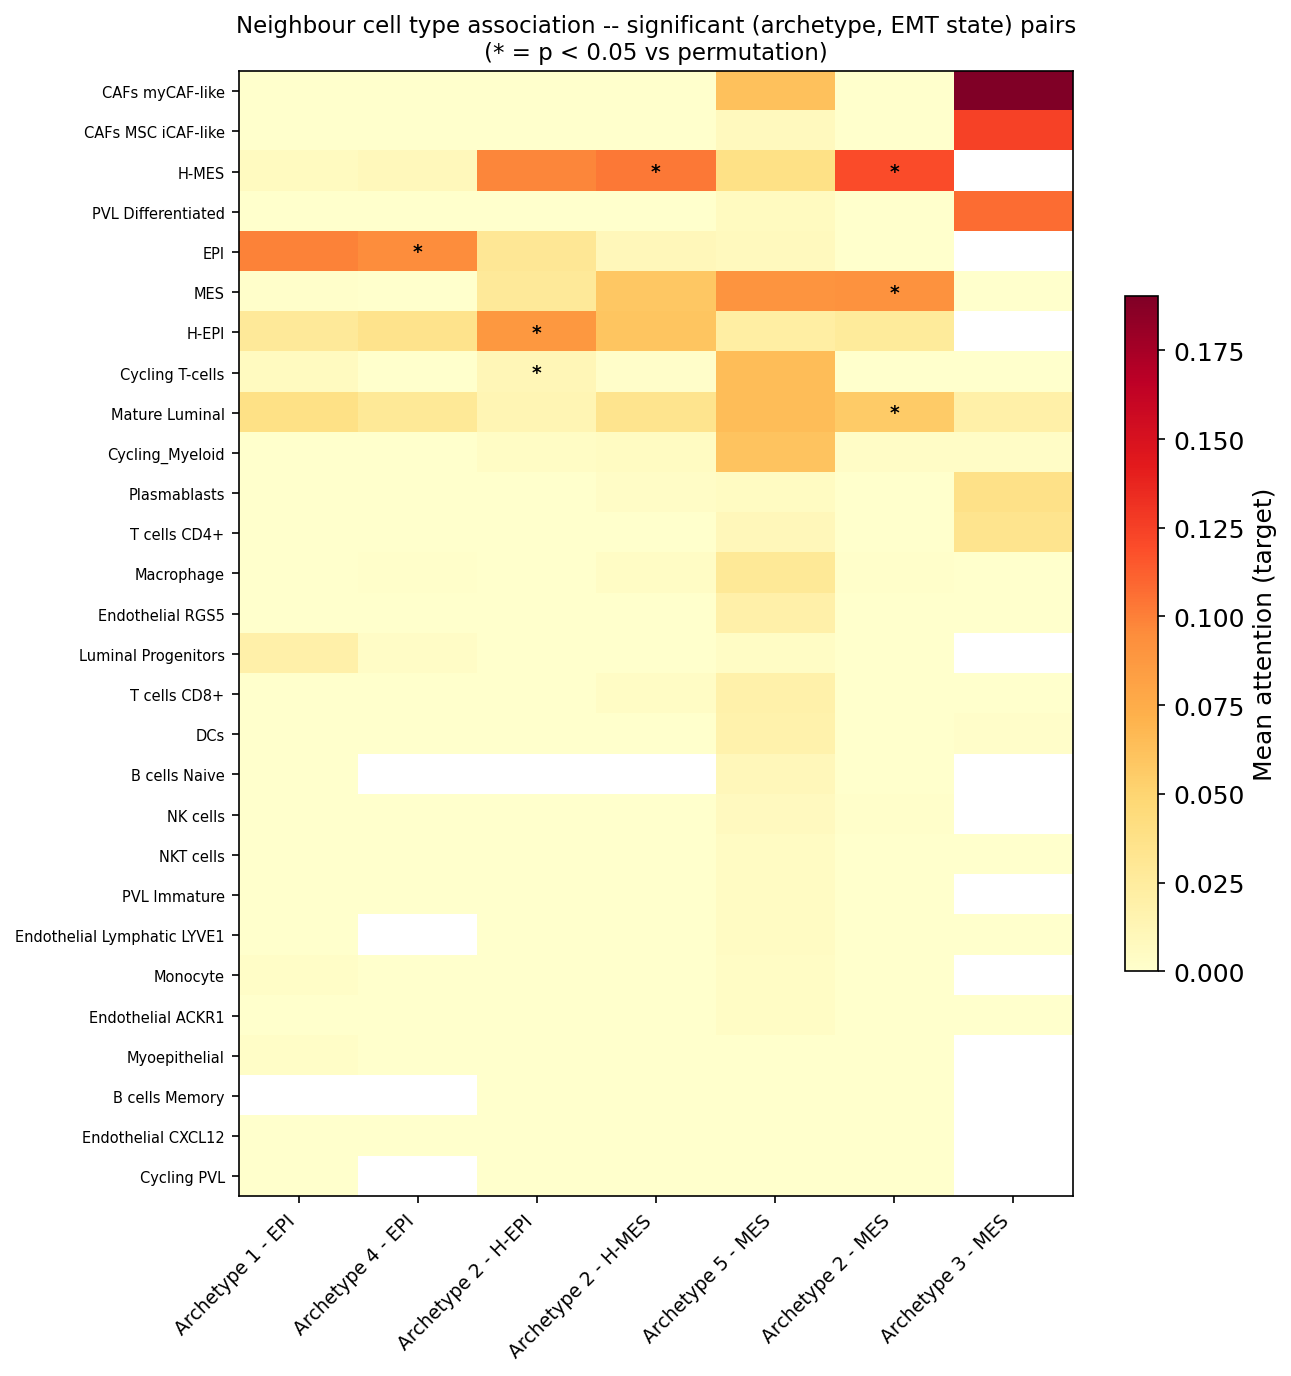

In [24]:
frames = [df.assign(pair_label=f"{arch} - {state}") for (arch, state), df in pair_dfs.items() if len(df)]
heat_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

if not heat_df.empty:
    importance = heat_df.pivot_table(index="neighbour_celltype", columns="pair_label", values="mean_importance_target")
    sig = heat_df.pivot_table(index="neighbour_celltype", columns="pair_label", values="p_value") < 0.05
    col_order = [f"{arch} - {state}" for arch, _, state in significant_pairs if f"{arch} - {state}" in importance.columns]
    row_order = importance.max(axis=1).sort_values(ascending=False).index
    importance, sig = importance.loc[row_order, col_order], sig.loc[row_order, col_order]

    vmax = np.nanmax(importance.values) if np.isfinite(importance.values).any() else 1.0
    fig, ax = plt.subplots(figsize=(0.9 * len(col_order) + 2.5, 0.28 * len(row_order) + 1.5))
    im = ax.imshow(importance.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(col_order)))
    ax.set_xticklabels(col_order, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(len(row_order)))
    ax.set_yticklabels(row_order, fontsize=7)
    for i in range(len(row_order)):
        for j in range(len(col_order)):
            if sig.values[i, j]:
                ax.text(j, i, "*", ha="center", va="center", color="black", fontsize=9, fontweight="bold")
    fig.colorbar(im, ax=ax, shrink=0.6, label="Mean attention (target)")
    ax.set_title("Neighbour cell type association -- significant (archetype, EMT state) pairs\n(* = p < 0.05 vs permutation)", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_archetype_state_neighbour_heatmaps.pdf"), bbox_inches="tight", dpi=300)
    plt.show()
else:
    print("No significant (archetype, EMT state) pairs -- nothing to plot.")

### Combined spoke-network panel — one row per archetype, one column per state

28 `plot_state_neighbours` panels (7 archetypes × 4 states) sharing one
colour scale, in a single figure.

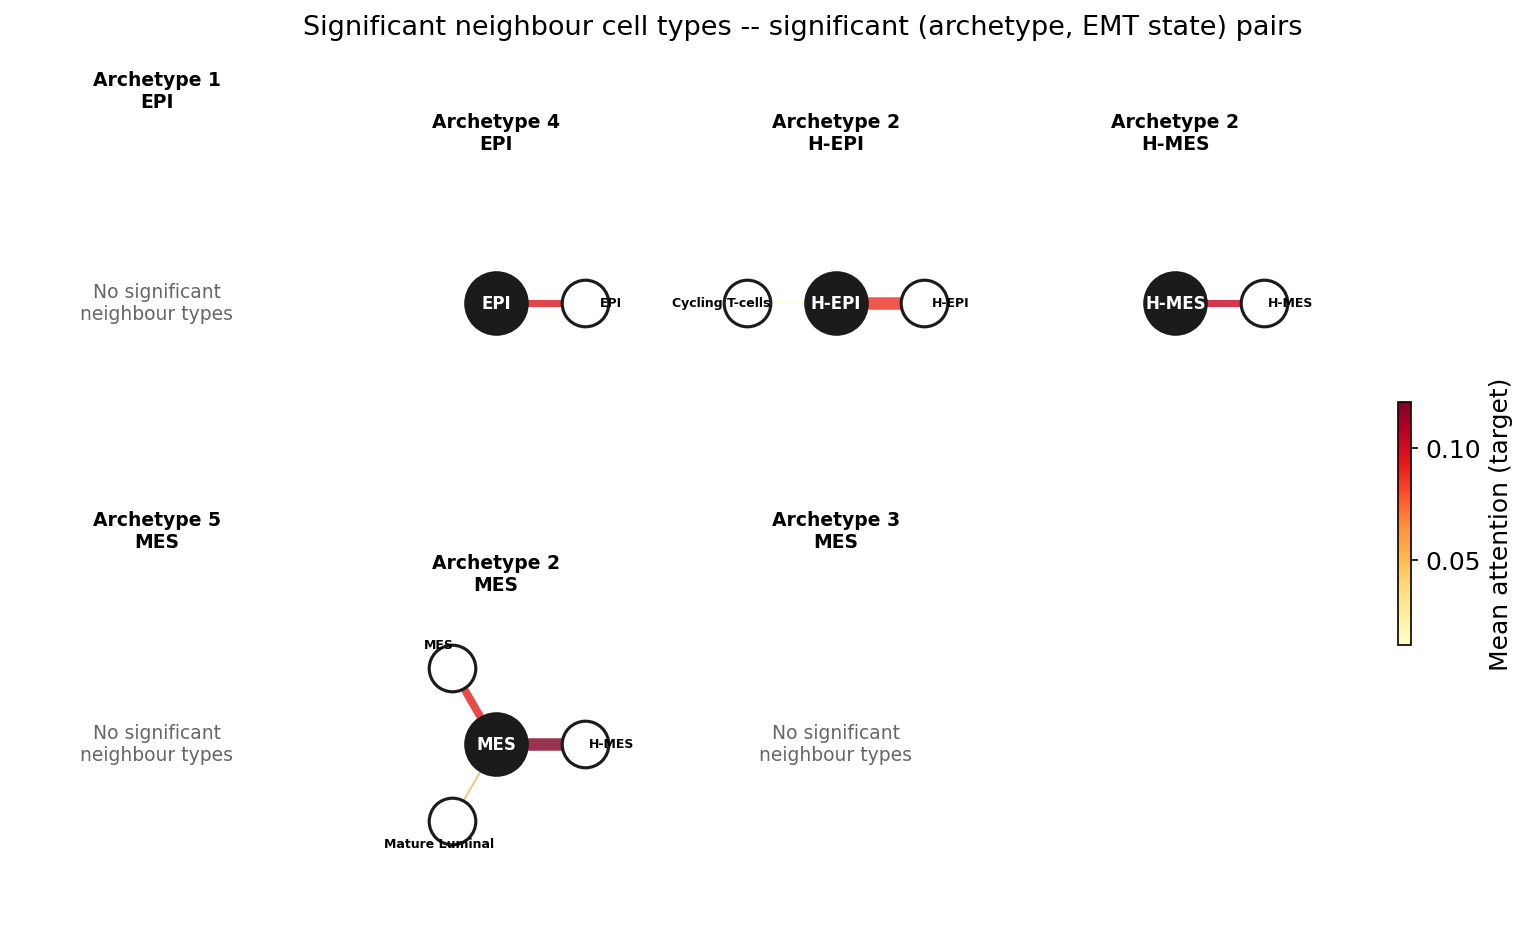

In [25]:
all_sig_weights = [
    w for df in pair_dfs.values()
    for w in df.loc[df["p_value"] < 0.05, "mean_importance_target"].tolist()
]
shared_norm = (
    mcolors.Normalize(vmin=min(all_sig_weights), vmax=max(all_sig_weights))
    if all_sig_weights else mcolors.Normalize(vmin=0, vmax=1)
)

n_pairs = len(pair_dfs)
if n_pairs:
    n_cols = min(n_pairs, 4)
    n_rows = int(np.ceil(n_pairs / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, squeeze=False, figsize=(3.5 * n_cols, 3.5 * n_rows))
    for idx, ((arch, state_name), df) in enumerate(pair_dfs.items()):
        ax = axes[idx // n_cols, idx % n_cols]
        plot_state_neighbours(df, hub_label=state_name, ax=ax, norm=shared_norm, alpha=0.05)
        ax.set_title(f"{arch}\n{state_name}", fontsize=9, fontweight="bold")
    for idx in range(n_pairs, n_rows * n_cols):
        axes[idx // n_cols, idx % n_cols].axis("off")
    fig.colorbar(
        cm.ScalarMappable(cmap="YlOrRd", norm=shared_norm),
        ax=axes, shrink=0.3, label="Mean attention (target)",
    )
    fig.suptitle("Significant neighbour cell types -- significant (archetype, EMT state) pairs", fontsize=13)
    fig.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_archetype_state_spoke_grid.pdf"), bbox_inches="tight", dpi=300)
    plt.show()
else:
    print("No significant (archetype, EMT state) pairs -- nothing to plot.")

## 5. Intrinsic vs spatial-effect genes — all significant genes labelled

Same classification as `05_simvi_run.ipynb` section 3b (Huber-regression
outlier detection on `r2_z` vs `r2_s`), but every gene classified as
`Intrinsic-specific` or `Spatial-induced` gets a text label here, instead
of only genes above a fixed `r2_s` cutoff.

42 / 217 genes labelled (30 intrinsic-specific, 12 spatial-induced)


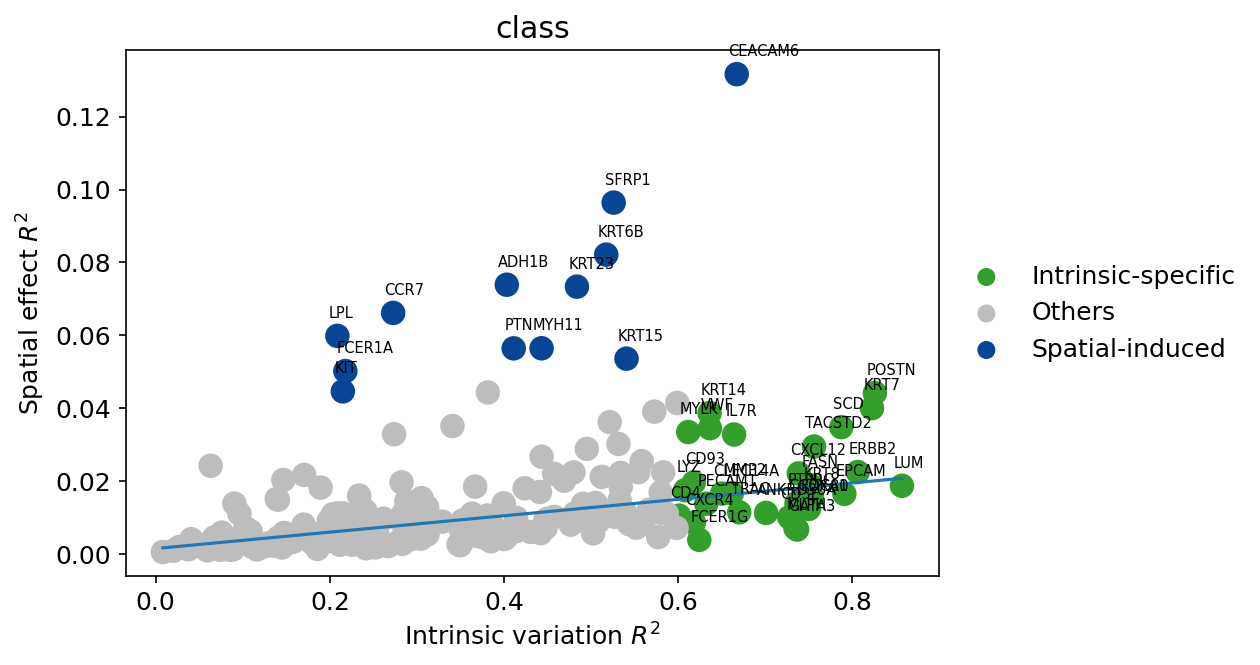

In [26]:
from sklearn.linear_model import HuberRegressor

adata_ = adata.copy()
sc.pp.highly_variable_genes(adata_, n_top_genes=300)
adata_ = adata_[:, adata_.var["means"] > 0.1].copy()

hr = HuberRegressor()
hr.fit(adata_.var["r2_z"].values.reshape(-1, 1), adata_.var["r2_s"].values)

adata_.var["class"] = "Others"
adata_.var.loc[adata_.var["r2_z"] > 0.6, "class"] = "Intrinsic-specific"
adata_.var.loc[
    np.abs(adata_.var["r2_s"].values - hr.predict(adata_.var["r2_z"].values.reshape(-1, 1)))
    / hr.scale_
    > 10,
    "class",
] = "Spatial-induced"

adata_.uns["class_colors"] = ["#33a02c", "#bdbdbd", "#084594"]

sc.pl.scatter(adata_.copy(), x="r2_z", y="r2_s", show=False, color="class")
order = np.argsort(adata_.var["r2_z"].values)
plt.plot(adata_.var["r2_z"].values[order], hr.predict(adata_.var["r2_z"].values.reshape(-1, 1))[order])

significant = adata_.var["class"] != "Others"
print(
    f"{significant.sum()} / {adata_.shape[1]} genes labelled "
    f"({(adata_.var['class'] == 'Intrinsic-specific').sum()} intrinsic-specific, "
    f"{(adata_.var['class'] == 'Spatial-induced').sum()} spatial-induced)"
)

for gene, row in adata_.var[significant].iterrows():
    plt.text(row["r2_z"] - 0.01, row["r2_s"] + 0.005, gene, fontsize=7)

plt.xlabel("Intrinsic variation $R^2$")
plt.ylabel("Spatial effect $R^2$")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_gene_classification_all_labels.pdf"), bbox_inches="tight", dpi=300)

## 6. squidpy neighbourhood enrichment, per (archetype, EMT state) pair

Model-free cross-check for section 4, recomputed for the same significant
`(archetype, EMT state)` pairs from section 3 -- one panel per pair, not
per archetype. Each panel's cell population is: every non-tumour cell in
that archetype (`celltype_minor`, unrestricted) **plus only the tumour
cells in that pair's specific EMT state** -- tumour cells belonging to a
*different* EMT state are excluded, even if they're also in this archetype
and even if that other state is separately significant for it (e.g.
`Archetype 2` is significant for all four states, so it gets four
separate panels here, each restricted to just that one state's tumour
cells, not a single panel mixing all four).

The spatial graph is rebuilt from scratch on each subset (`spatial`
coordinates are still present after subsetting) rather than reusing the
full-dataset graph, since slicing it would leave cells whose original
neighbours fell outside the subset with an incomplete/broken neighbourhood.

In [27]:
archetype_nhood_z = {}
tumour_mask_all = (adata.obs["state_label"] >= 0).values
for arch, label_val, state_name in significant_pairs:
    arch_mask = archetype_membership[arch].values
    this_state_mask = adata.obs["state_label"].values == label_val
    keep = arch_mask & (~tumour_mask_all | this_state_mask)
    sub = adata[keep].copy()
    sub.obs["celltype_or_state"] = sub.obs["celltype_or_state"].cat.remove_unused_categories()
    key = (arch, state_name)
    if sub.n_obs < 50 or sub.obs["celltype_or_state"].nunique() < 2:
        archetype_nhood_z[key] = None
        print(f"{arch} - {state_name}: skipped ({sub.n_obs} cells, {sub.obs['celltype_or_state'].nunique()} categories)")
        continue
    sq.gr.spatial_neighbors(sub, n_neighs=12, coord_type="generic")
    sq.gr.nhood_enrichment(sub, cluster_key="celltype_or_state", seed=0)
    z = pd.DataFrame(
        sub.uns["celltype_or_state_nhood_enrichment"]["zscore"],
        index=sub.obs["celltype_or_state"].cat.categories,
        columns=sub.obs["celltype_or_state"].cat.categories,
    )
    archetype_nhood_z[key] = z
    print(f"{arch} - {state_name}: {sub.n_obs} cells, {z.shape[0]} categories")

  0%|          | 0/1000 [00:00<?, ?/s]

Archetype 1 - EPI: 4005 cells, 13 categories


  0%|          | 0/1000 [00:00<?, ?/s]

Archetype 4 - EPI: 5371 cells, 10 categories


  0%|          | 0/1000 [00:00<?, ?/s]

Archetype 2 - H-EPI: 9228 cells, 14 categories


... (4 outputs left out)

  0%|          | 0/1000 [00:00<?, ?/s]

Archetype 2 - MES: 9896 cells, 14 categories


  0%|          | 0/1000 [00:00<?, ?/s]

Archetype 3 - MES: 4063 cells, 24 categories


28 categories (row/column order, same for every panel below):
['B cells Memory', 'B cells Naive', 'CAFs MSC iCAF-like', 'CAFs myCAF-like', 'Cycling PVL', 'Cycling T-cells', 'Cycling_Myeloid', 'DCs', 'EPI', 'Endothelial ACKR1', 'Endothelial CXCL12', 'Endothelial Lymphatic LYVE1', 'Endothelial RGS5', 'H-EPI', 'H-MES', 'Luminal Progenitors', 'MES', 'Macrophage', 'Mature Luminal', 'Monocyte', 'Myoepithelial', 'NK cells', 'NKT cells', 'PVL Differentiated', 'PVL Immature', 'Plasmablasts', 'T cells CD4+', 'T cells CD8+']
Archetype 1 - EPI: vmax=11.6 (95th pct of off-diagonal |z|; observed max |z|=91.0)
Archetype 4 - EPI: vmax=20.6 (95th pct of off-diagonal |z|; observed max |z|=50.6)
Archetype 2 - H-EPI: vmax=10.0 (95th pct of off-diagonal |z|; observed max |z|=58.6)
Archetype 2 - H-MES: vmax=5.0 (95th pct of off-diagonal |z|; observed max |z|=38.8)
Archetype 5 - MES: vmax=8.5 (95th pct of off-diagonal |z|; observed max |z|=38.8)
Archetype 2 - MES: vmax=5.3 (95th pct of off-diagonal |z|; obse

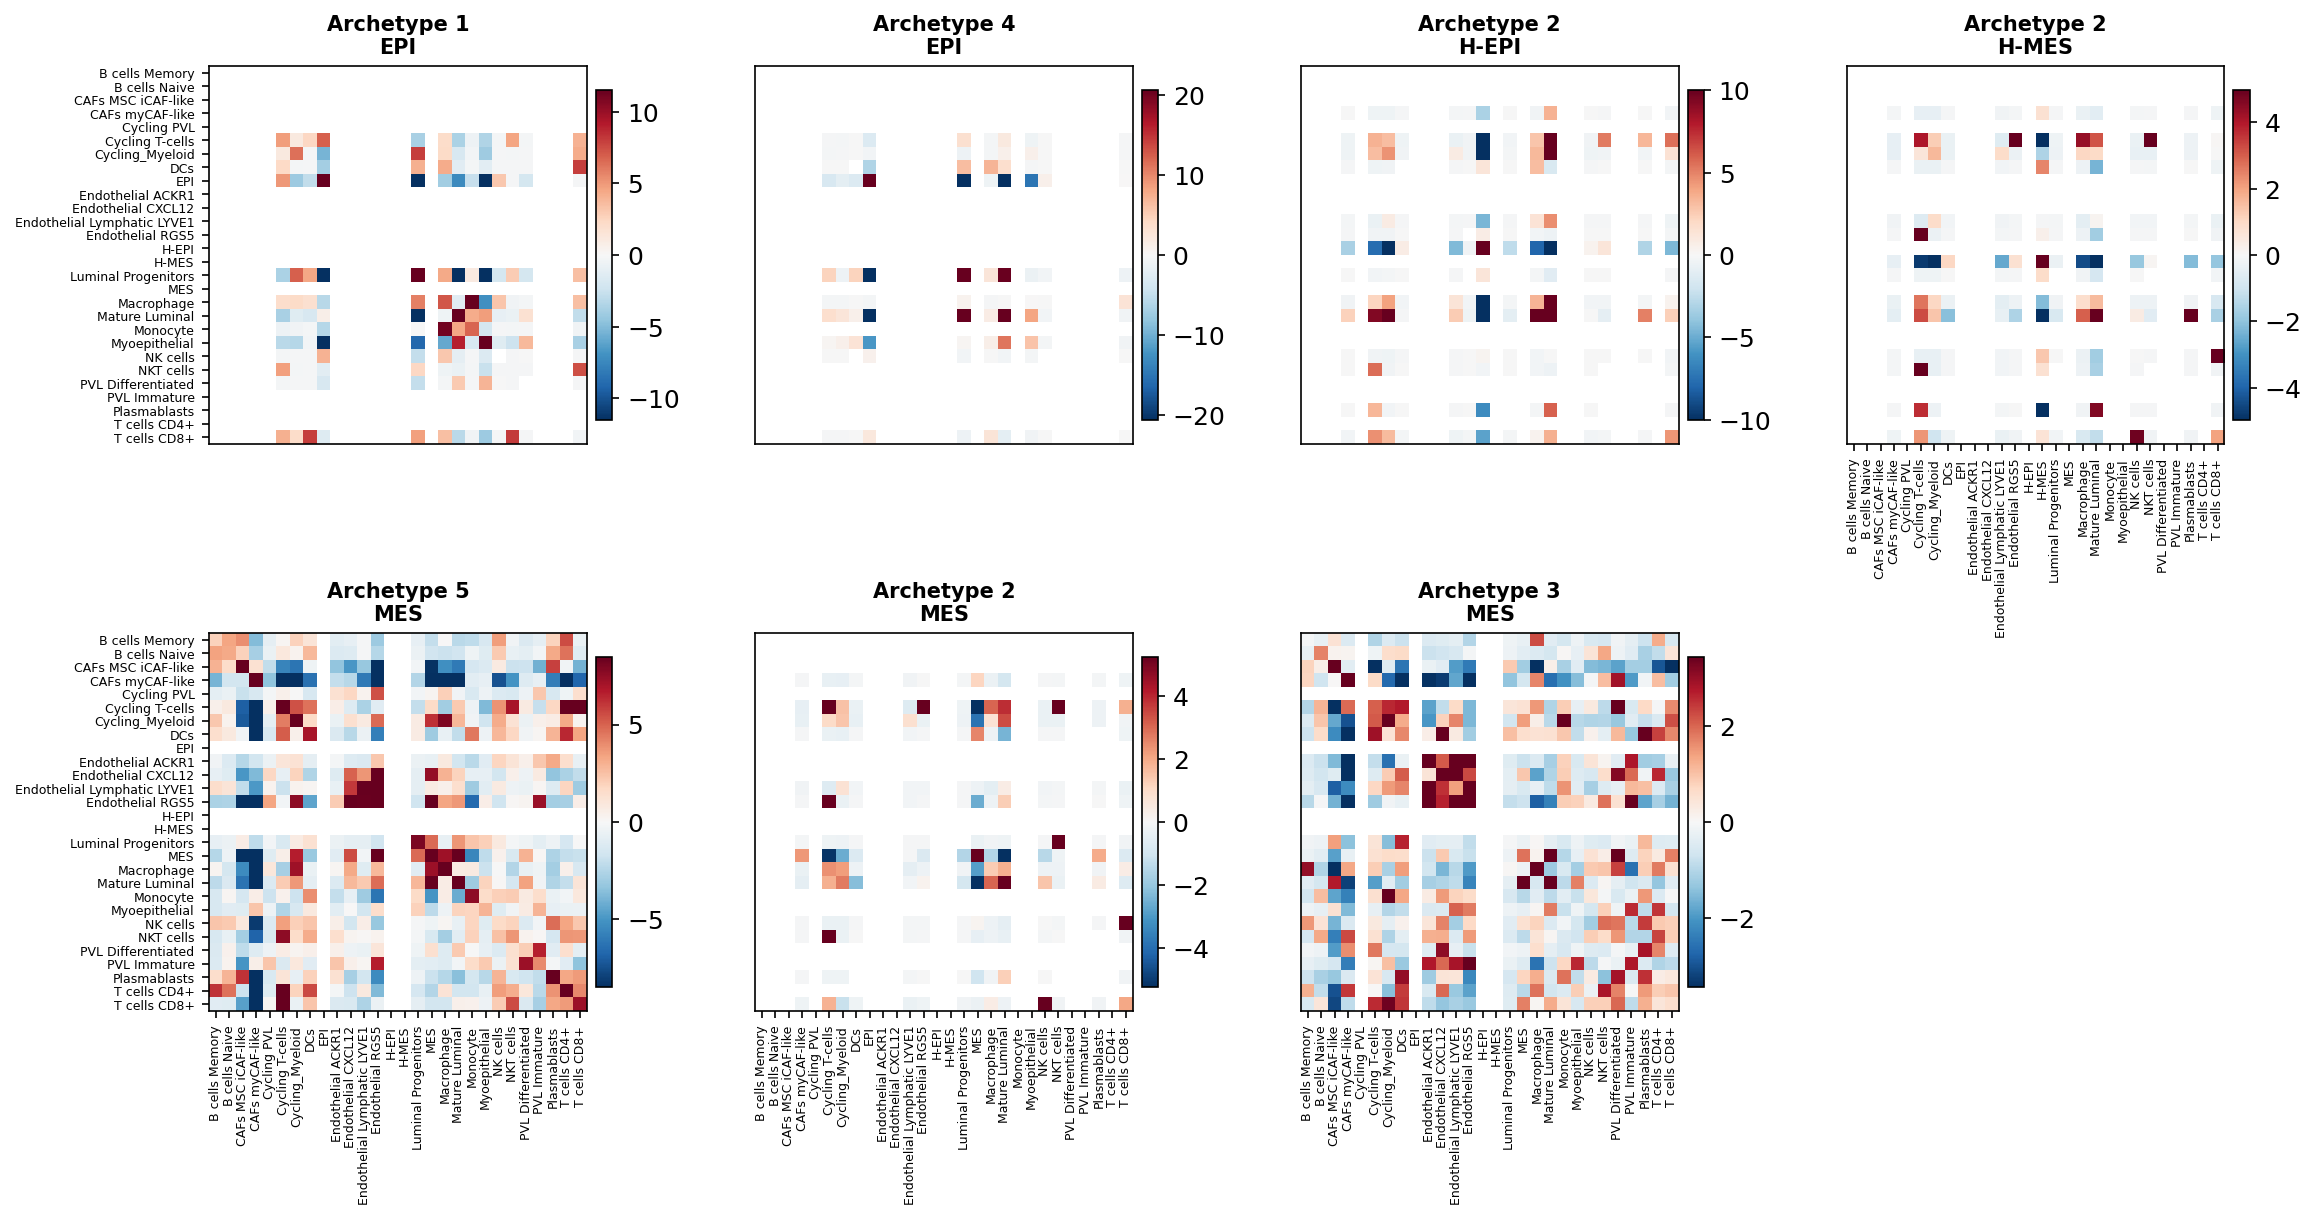

In [28]:
all_categories = sorted(set().union(*[z.index for z in archetype_nhood_z.values() if z is not None]))
print(f"{len(all_categories)} categories (row/column order, same for every panel below):")
print(all_categories)


def archetype_zscore_vmax(z, percentile=95, floor=1.0):
    '''Colour-scale cap for one pair's own z-score matrix: the given
    percentile of |z| among *off-diagonal* entries. Diagonal (self-self)
    pairs are typically the strongest signal by construction and would
    otherwise dominate the scale even within a single panel; they still
    get plotted, just saturated if they exceed this cap. squidpy's
    neighbourhood-enrichment z-score is an *unnormalised* permutation
    z-score (not bounded like a correlation), and pairs here can span very
    different magnitudes, so a single shared cap makes smaller-magnitude
    pairs look blank. Per-pair caps fix that, at the cost of the colour no
    longer being directly comparable in magnitude across panels (each
    panel prints its own cap below).'''
    vals = z.values.copy()
    np.fill_diagonal(vals, np.nan)
    finite = np.abs(vals[np.isfinite(vals)])
    if finite.size == 0:
        return floor
    return max(np.percentile(finite, percentile), floor)


pair_vmax = {}
for key, z in archetype_nhood_z.items():
    if z is None:
        continue
    vmax = archetype_zscore_vmax(z)
    pair_vmax[key] = vmax
    finite_all = np.abs(z.values[np.isfinite(z.values)])
    observed_max = finite_all.max() if finite_all.size else 0.0
    arch, state_name = key
    print(f"{arch} - {state_name}: vmax={vmax:.1f} (95th pct of off-diagonal |z|; observed max |z|={observed_max:.1f})")

nhood_pairs = list(archetype_nhood_z.keys())
if nhood_pairs:
    n_cols = min(4, len(nhood_pairs))
    n_rows = max(int(np.ceil(len(nhood_pairs) / n_cols)), 1)
    fig, axes = plt.subplots(n_rows, n_cols, squeeze=False, figsize=(4.5 * n_cols, 4.5 * n_rows))

    for k, key in enumerate(nhood_pairs):
        arch, state_name = key
        row, col = k // n_cols, k % n_cols
        ax = axes[row, col]
        z = archetype_nhood_z[key]
        if z is None:
            ax.text(0.5, 0.5, "Too few cells", ha="center", va="center", transform=ax.transAxes, fontsize=9, color="#666666")
            ax.set_title(f"{arch}\n{state_name}", fontsize=10, fontweight="bold")
            ax.axis("off")
            continue
        vmax = pair_vmax[key]
        z_full = z.reindex(index=all_categories, columns=all_categories)
        im = ax.imshow(z_full.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
        ax.set_title(f"{arch}\n{state_name}", fontsize=10, fontweight="bold")

        is_bottom_row = row == n_rows - 1 or k + n_cols >= len(nhood_pairs)
        if col == 0:
            ax.set_yticks(range(len(all_categories)))
            ax.set_yticklabels(all_categories, fontsize=6)
        else:
            ax.set_yticks([])
        if is_bottom_row:
            ax.set_xticks(range(len(all_categories)))
            ax.set_xticklabels(all_categories, fontsize=6, rotation=90)
        else:
            ax.set_xticks([])

    for k in range(len(nhood_pairs), n_rows * n_cols):
        axes[k // n_cols, k % n_cols].axis("off")

    fig.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_archetype_nhood_enrichment_grid.pdf"), bbox_inches="tight", dpi=300)
    plt.show()
else:
    print("No significant (archetype, EMT state) pairs -- nothing to plot.")

### Clustered version — cell types reordered by enrichment-profile similarity

The grid above uses one shared category order (alphabetical) so panels
line up row-for-row. Here each archetype's own matrix is independently
hierarchically clustered instead — categories are grouped by how similar
their *row* of z-scores is to every other category's (the same approach
`seaborn.clustermap` uses by default: Euclidean distance between rows,
average linkage), which pulls blocks of cell types that consistently
associate with each other into contiguous blocks on the diagonal.

Trade-off: because each panel is clustered on its own data, the row/column
order differs archetype to archetype, so panels are no longer directly
comparable position-by-position the way the shared-order grid above is —
this view is for spotting within-archetype structure (which cell types
cluster together), not for comparing the same row across archetypes.

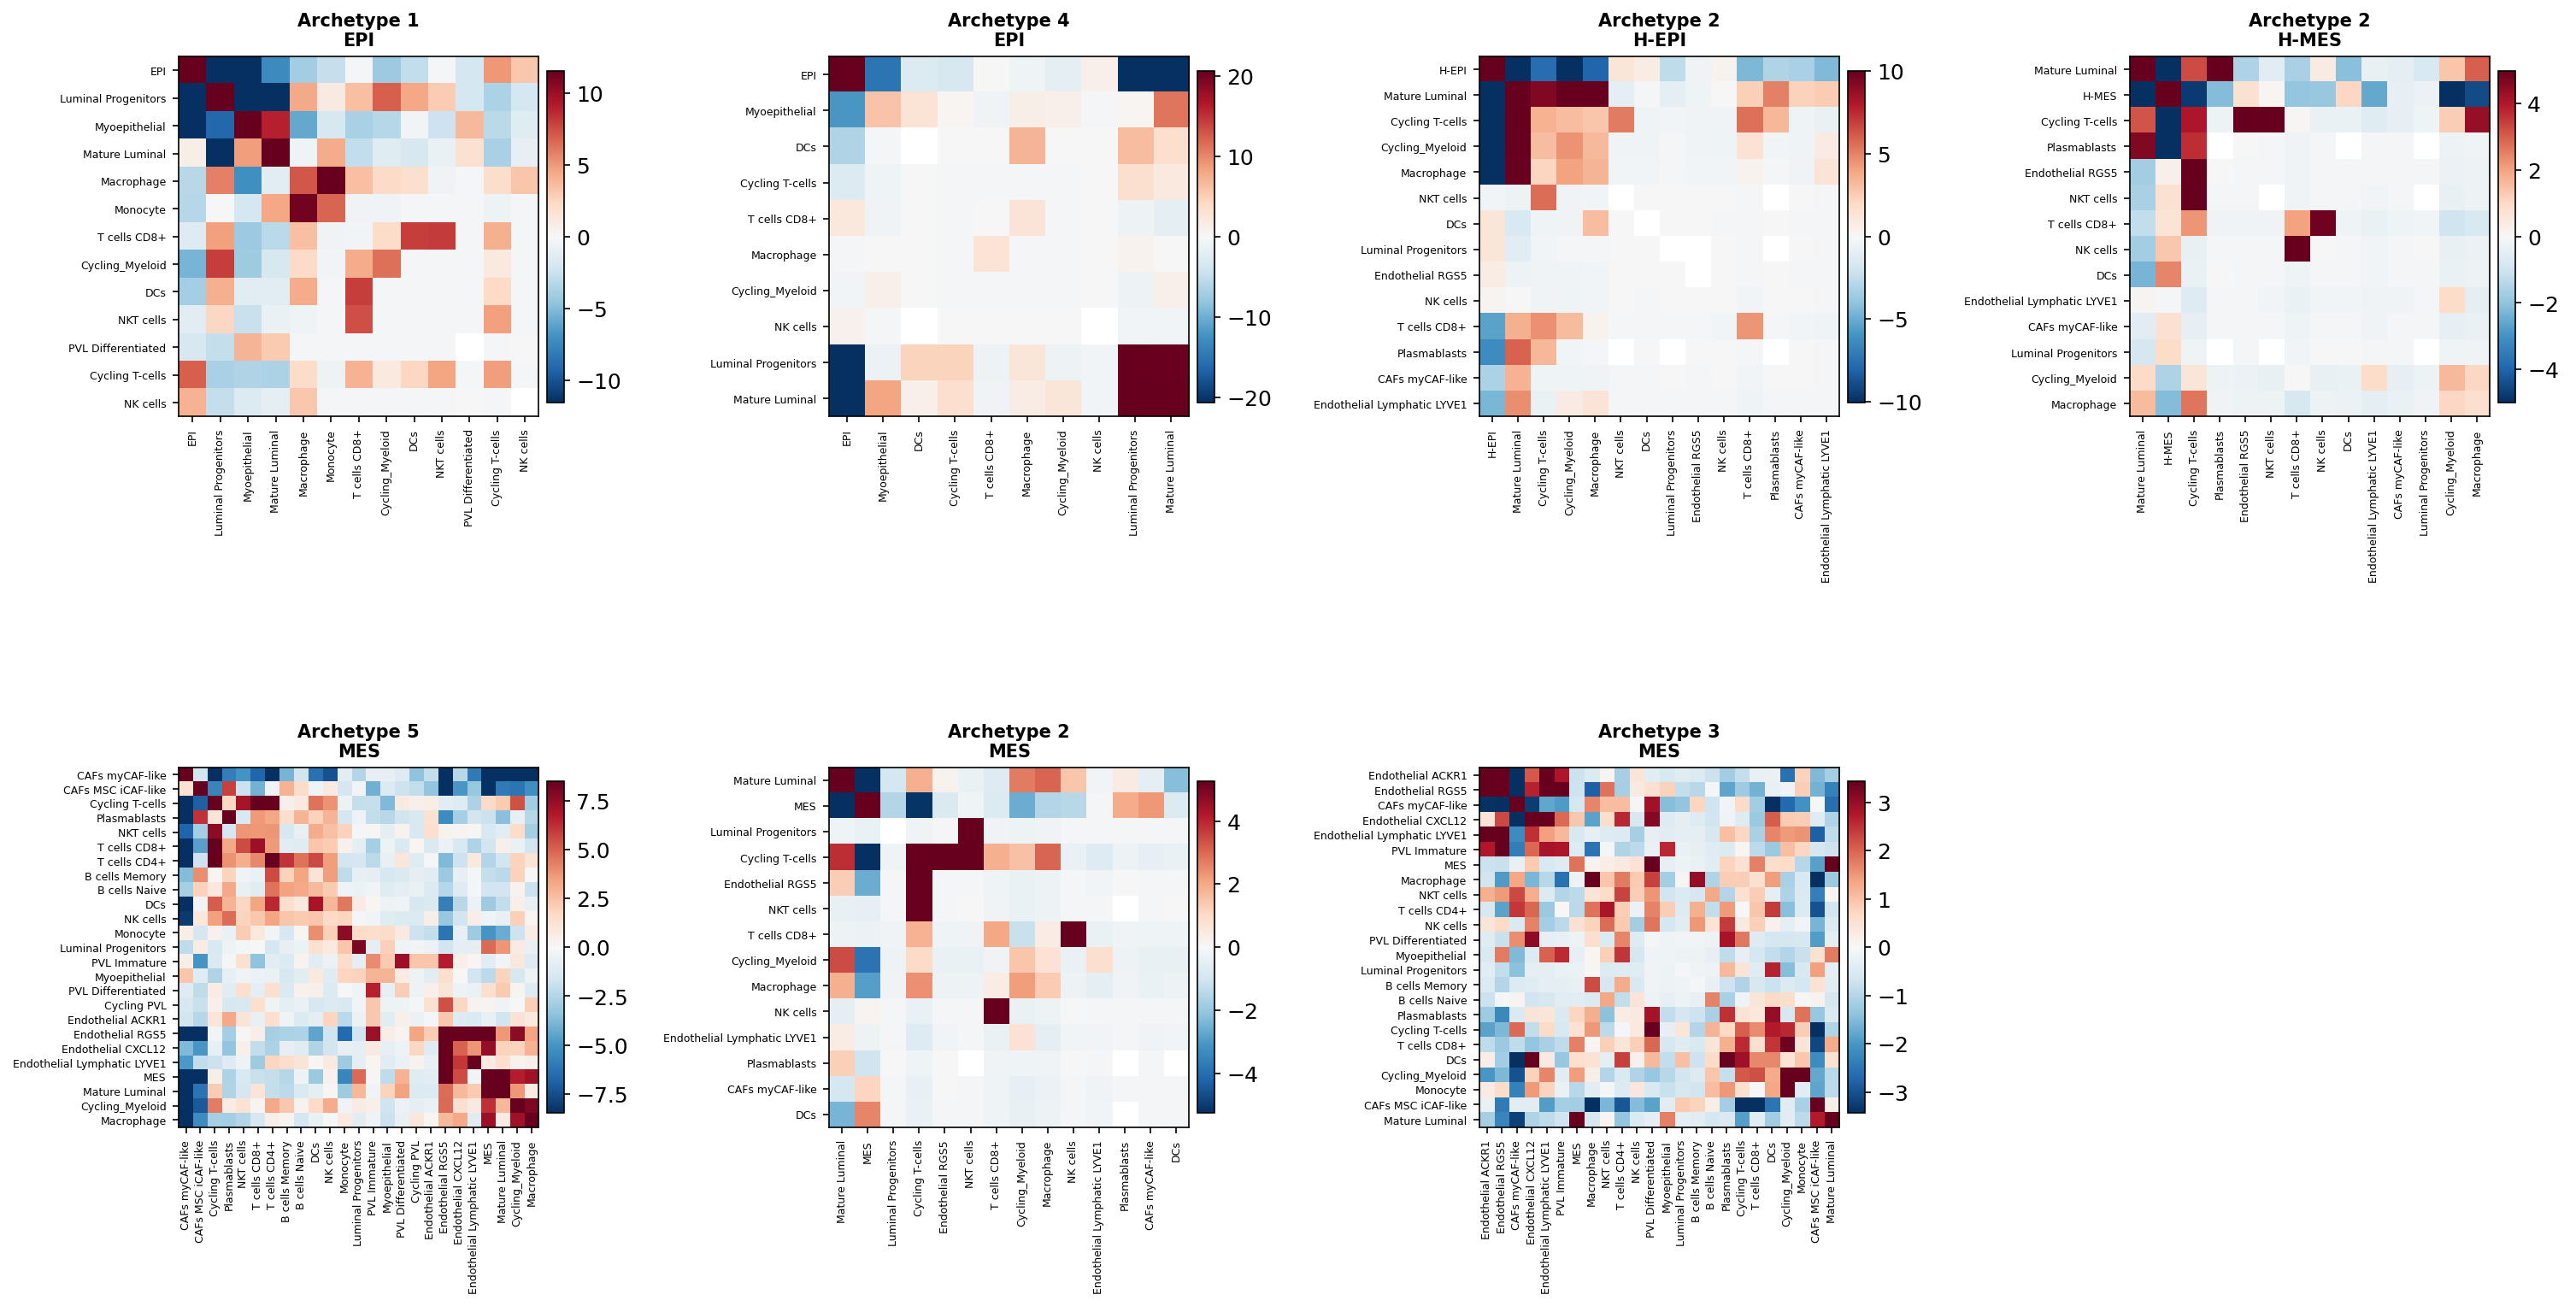

In [29]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist


def cluster_order(z, method="average", metric="euclidean"):
    '''Hierarchical-clustering leaf order for a symmetric enrichment
    matrix, based on each category's row profile (its z-scores against
    every other category) -- NaN entries (categories too rare for a
    stable z-score against each other) are filled with 0 for this
    purpose only.'''
    if z.shape[0] < 3:
        return z.index
    vals = np.nan_to_num(z.values, nan=0.0)
    dist = pdist(vals, metric=metric)
    Z = linkage(dist, method=method)
    return z.index[leaves_list(Z)]


if nhood_pairs:
    n_cols = min(4, len(nhood_pairs))
    n_rows = max(int(np.ceil(len(nhood_pairs) / n_cols)), 1)
    fig, axes = plt.subplots(n_rows, n_cols, squeeze=False, figsize=(6 * n_cols, 6 * n_rows))

    for k, key in enumerate(nhood_pairs):
        arch, state_name = key
        ax = axes[k // n_cols, k % n_cols]
        z = archetype_nhood_z[key]
        if z is None:
            ax.text(0.5, 0.5, "Too few cells", ha="center", va="center", transform=ax.transAxes, fontsize=9, color="#666666")
            ax.set_title(f"{arch}\n{state_name}", fontsize=10, fontweight="bold")
            ax.axis("off")
            continue
        order = cluster_order(z)
        z_ord = z.loc[order, order]
        vmax = pair_vmax[key]
        im = ax.imshow(z_ord.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
        ax.set_title(f"{arch}\n{state_name}", fontsize=10, fontweight="bold")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, fontsize=6, rotation=90)
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels(order, fontsize=6)

    for k in range(len(nhood_pairs), n_rows * n_cols):
        axes[k // n_cols, k % n_cols].axis("off")

    fig.subplots_adjust(
        wspace=0.5,  # horizontal space between panels
        hspace=0.5,  # vertical space between panels
    )

    fig.savefig(
        os.path.join(FIGURES_DIR, "xenium_v1_simvi_archetype_nhood_enrichment_grid_clustered.pdf"),
        bbox_inches="tight", dpi=300,
    )
    plt.show()
else:
    print("No significant (archetype, EMT state) pairs -- nothing to plot.")

## 7. Save results

In [30]:
fisher_df.to_csv("simvi_archetype_state_fisher.csv", index=False)

rows = []
for arch, res in archetype_state_neighbours.items():
    for label_val, df in res.items():
        if not len(df):
            continue
        d = df.copy()
        d.insert(0, "archetype", arch)
        d.insert(1, "EMT_state", EMT_MAP[label_val])
        rows.append(d)
if rows:
    pd.concat(rows, ignore_index=True).to_csv("simvi_archetype_state_neighbours.csv", index=False)
else:
    print("No archetype-state neighbour results to save.")

for (arch, state_name), z in archetype_nhood_z.items():
    if z is not None:
        safe_name = f"{arch}_{state_name}".replace(" ", "_")
        z.to_csv(f"simvi_archetype_nhood_enrichment_{safe_name}.csv")